Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cifar10/incomplete.RVSLUT_3.0.2/cifar10-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cifar10/incomplete.RVSLUT_3.0.2/cifar10-test.tfrecord-[0-9][0-9][0-9][0-9]…

Dataset cifar10 downloaded and prepared to /root/tensorflow_datasets/cifar10/3.0.2. Subsequent calls will reuse this data.
Training set shape: (50000, 32, 32, 3) (50000, 1)
Test set shape: (10000, 32, 32, 3) (10000, 1)


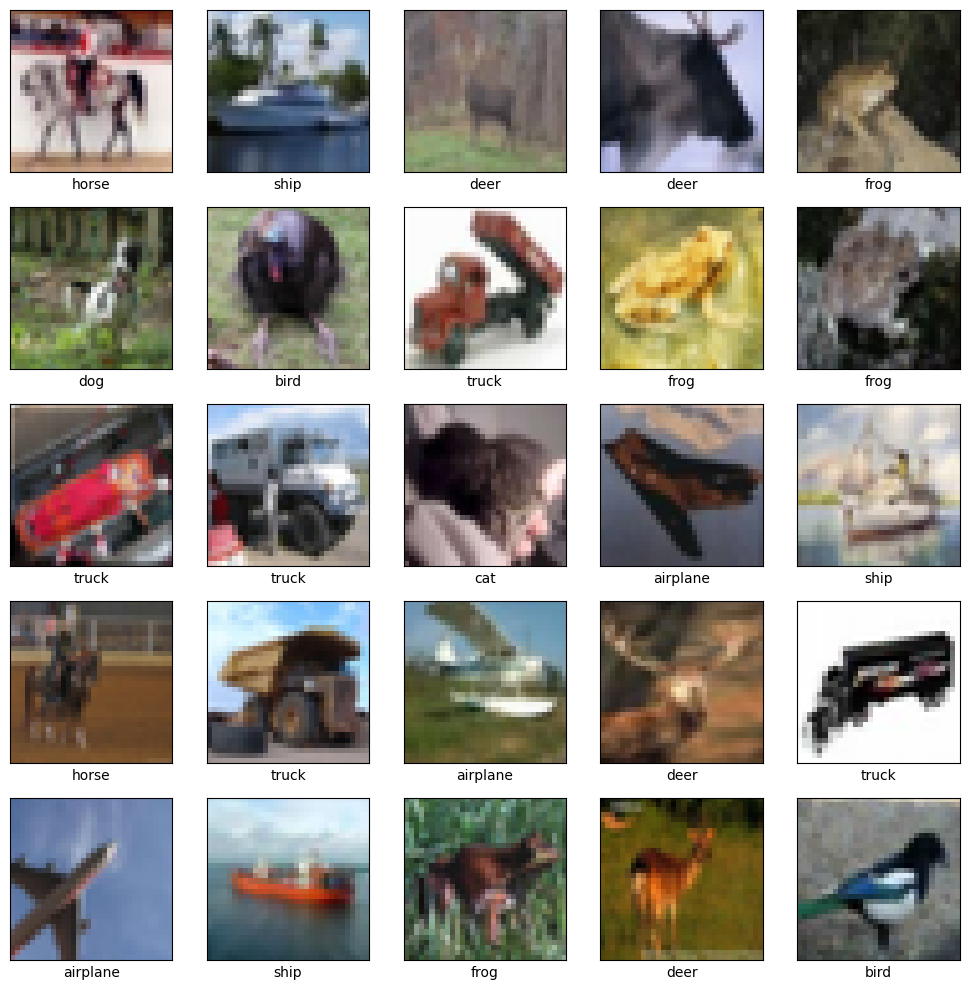

In [4]:
!pip install -q importlib_resources

import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models, preprocessing
import matplotlib.pyplot as plt
import numpy as np
import time
import os

# Download CIFAR-10 from Google Cloud fast mirror (~5 seconds)
train_data, test_data = tfds.as_numpy(
    tfds.load('cifar10', split=['train', 'test'], batch_size=-1, as_supervised=True)
)

raw_train_x, raw_train_y = train_data
raw_test_x, raw_test_y = test_data

train_images = raw_train_x.astype('float32') / 255.0
train_labels = raw_train_y.reshape(-1, 1)

test_images = raw_test_x.astype('float32') / 255.0
test_labels = raw_test_y.reshape(-1, 1)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Training set shape:", train_images.shape, train_labels.shape)
print("Test set shape:", test_images.shape, test_labels.shape)

# Plot first 25 images from training dataset
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])

plt.tight_layout()
plt.show()



In [5]:
def create_cnn():
    model = models.Sequential()

    model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(10))

    return model

model = create_cnn()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

--- Training CNN with SGD Optimizer ---
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.2287 - loss: 2.0882 - val_accuracy: 0.3273 - val_loss: 1.8588
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.3842 - loss: 1.7098 - val_accuracy: 0.4387 - val_loss: 1.5500
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4639 - loss: 1.4938 - val_accuracy: 0.4530 - val_loss: 1.5176
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5081 - loss: 1.3749 - val_accuracy: 0.4812 - val_loss: 1.4496
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5446 - loss: 1.2867 - val_accuracy: 0.5537 - val_loss: 1.2527
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5735 - loss: 1.2089 - val_accuracy: 0.5418 - val_loss: 1.2701
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5994 - loss: 1.1416 - val_accuracy: 0.5693 - val_loss: 1.2309
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms

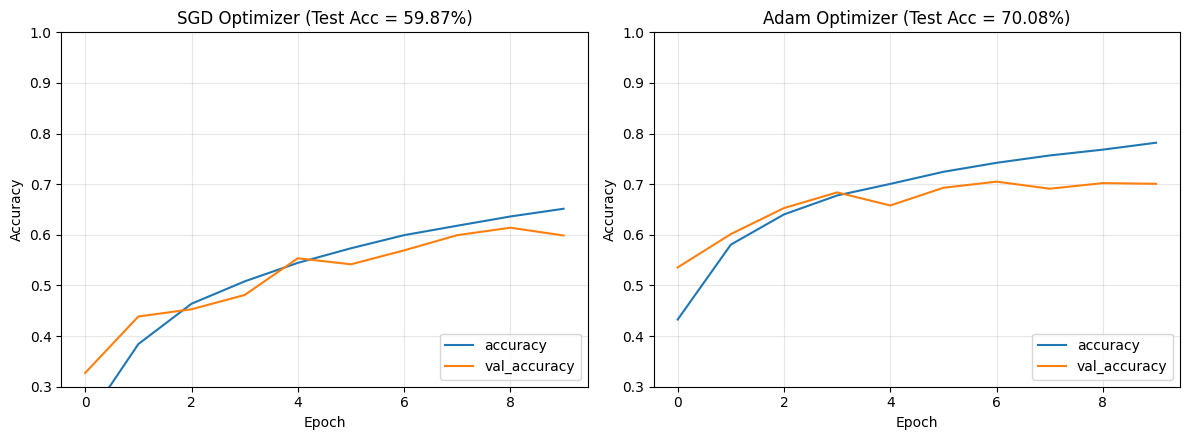

Saved '/content/final_model.keras' successfully!


In [6]:
print("--- Training CNN with SGD Optimizer ---")
sgd_model = create_cnn()
sgd_model.compile(
    optimizer='sgd',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
history_sgd = sgd_model.fit(
    train_images, train_labels, epochs=10,
    validation_data=(test_images, test_labels)
)
sgd_loss, sgd_acc = sgd_model.evaluate(test_images, test_labels, verbose=2)
print(f"Final Test Accuracy (SGD): {sgd_acc * 100:.2f}%\n")

print("--- Training CNN with Adam Optimizer ---")
adam_model = create_cnn()
adam_model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
history_adam = adam_model.fit(
    train_images, train_labels, epochs=10,
    validation_data=(test_images, test_labels)
)
test_loss, test_acc = adam_model.evaluate(test_images, test_labels, verbose=2)
print(f"Final Test Accuracy (Adam): {test_acc * 100:.2f}%")

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history_sgd.history['accuracy'], label='accuracy')
plt.plot(history_sgd.history['val_accuracy'], label='val_accuracy')
plt.title(f'SGD Optimizer (Test Acc = {sgd_acc*100:.2f}%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.3, 1.0])
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_adam.history['accuracy'], label='accuracy')
plt.plot(history_adam.history['val_accuracy'], label='val_accuracy')
plt.title(f'Adam Optimizer (Test Acc = {test_acc*100:.2f}%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.3, 1.0])
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

adam_model.save('/content/final_model.keras')
print("Saved '/content/final_model.keras' successfully!")


Image: sample_image.png -> Prediction: deer (Confidence: 74.43%)
Image: own_image1.png -> Prediction: automobile (Confidence: 71.89%)
Image: own_image2.png -> Prediction: deer (Confidence: 29.70%)


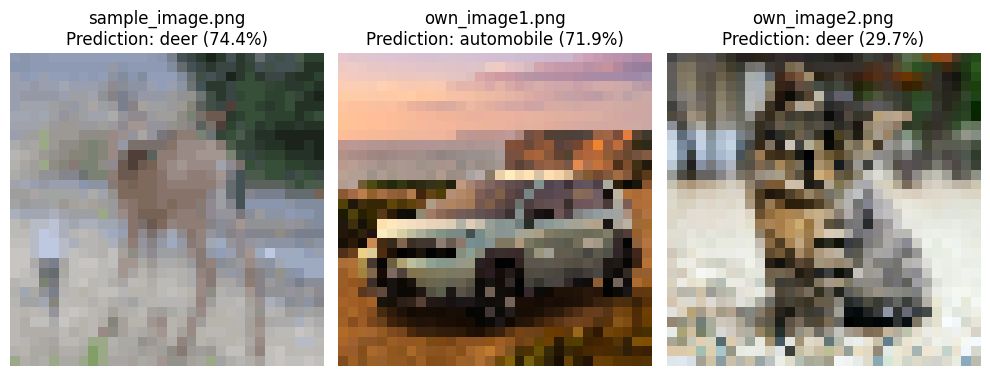

In [8]:
def load_image(filepath):
    img = preprocessing.image.load_img(filepath, target_size=(32, 32))
    arr = preprocessing.image.img_to_array(img)
    arr = arr.reshape(1, 32, 32, 3).astype('float32') / 255.0
    return img, arr

model = models.load_model('/content/final_model.keras')
prob_model = tf.keras.Sequential([model, layers.Softmax()])

image_files = [
    '/content/sample_image.png',
    '/content/own_image1.png',
    '/content/own_image2.png'
]

plt.figure(figsize=(10, 4))
for i, fpath in enumerate(image_files):
    fname = os.path.basename(fpath)
    if not os.path.exists(fpath):
        print(f"[Warning] Please upload '{fname}' to the left Files panel first!")
        continue

    disp_img, input_tensor = load_image(fpath)
    preds = prob_model.predict(input_tensor, verbose=0)[0]
    best_idx = np.argmax(preds)
    pred_label = class_names[best_idx]
    conf = preds[best_idx] * 100.0

    print(f"Image: {fname} -> Prediction: {pred_label} (Confidence: {conf:.2f}%)")

    plt.subplot(1, 3, i + 1)
    plt.imshow(disp_img)
    plt.title(f"{fname}\nPrediction: {pred_label} ({conf:.1f}%)")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [9]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = '/content/final_model_quantized.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

orig_kb = os.path.getsize('/content/final_model.keras') / 1024.0
quant_kb = os.path.getsize(tflite_path) / 1024.0

sample_batch = test_images[:200].astype('float32')

t0 = time.perf_counter()
for i in range(200):
    _ = model(sample_batch[i:i+1], training=False)
orig_ms = ((time.perf_counter() - t0) / 200.0) * 1000.0

interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
in_idx = interpreter.get_input_details()[0]['index']
out_idx = interpreter.get_output_details()[0]['index']

t0 = time.perf_counter()
for i in range(200):
    interpreter.set_tensor(in_idx, sample_batch[i:i+1])
    interpreter.invoke()
    _ = interpreter.get_tensor(out_idx)
quant_ms = ((time.perf_counter() - t0) / 200.0) * 1000.0

correct = 0
for i in range(len(test_images)):
    interpreter.set_tensor(in_idx, test_images[i:i+1].astype('float32'))
    interpreter.invoke()
    pred_c = np.argmax(interpreter.get_tensor(out_idx)[0])
    if pred_c == test_labels[i][0]:
        correct += 1
quant_acc = correct / len(test_images)

print("=== Optimization Benchmark Results ===")
print(f"Baseline Keras Model   -> Size: {orig_kb:.1f} KB | Speed: {orig_ms:.2f} ms/frame ({1000/orig_ms:.1f} FPS) | Test Acc: {test_acc*100:.2f}%")
print(f"Quantized TFLite Model -> Size: {quant_kb:.1f} KB | Speed: {quant_ms:.2f} ms/frame ({1000/quant_ms:.1f} FPS) | Test Acc: {quant_acc*100:.2f}%")
print(f"Compression Ratio: {orig_kb / quant_kb:.2f}x smaller | Speedup: {orig_ms / quant_ms:.2f}x faster")


Saved artifact at '/tmp/tmpzg68b477'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  132042330630160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330628048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330628240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330627664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330627856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330626128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330626320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330625744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330625936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132042330624208: TensorSpec(shape=(), dtype=tf.resource, name=None)
=== Optimization

=== Webots E-puck Camera CNN Prediction ===
Top-1 Prediction: frog (71.17% confidence)
  Top-1: frog (71.17%)
  Top-2: bird (23.02%)
  Top-3: deer (4.31%)


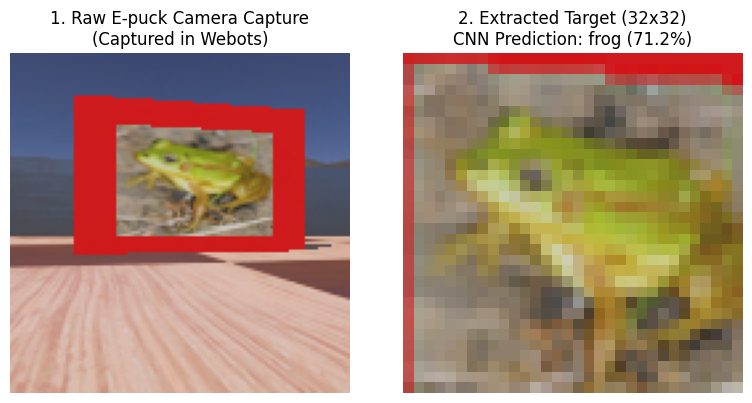

In [10]:
from PIL import Image

raw_path = '/content/webots_full_001.jpg'
if os.path.exists(raw_path):
    raw_img = Image.open(raw_path).convert('RGB')
    raw_np = np.array(raw_img)

    # Locate pure-red border in the photo and crop inside it to extract the frog
    red_mask = (raw_np[:, :, 0] > 110) & (raw_np[:, :, 1] < 55) & (raw_np[:, :, 2] < 55)
    ys, xs = np.where(red_mask)

    if len(xs) > 20:
        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()
        bw, bh = x2 - x1, y2 - y1
        ix1 = int(x1 + bw * 0.18)
        ix2 = int(x2 - bw * 0.18)
        iy1 = int(y1 + bh * 0.18)
        iy2 = int(y2 - bh * 0.18)
        inner_crop = raw_img.crop((ix1, iy1, ix2, iy2))
    else:
        w, h = raw_img.size
        inner_crop = raw_img.crop((int(w*0.25), int(h*0.25), int(w*0.75), int(h*0.75)))

    cnn_input_img = inner_crop.resize((32, 32))
    arr = np.array(cnn_input_img, dtype='float32').reshape(1, 32, 32, 3) / 255.0

    preds = prob_model.predict(arr, verbose=0)[0]
    top3_idx = np.argsort(preds)[::-1][:3]
    pred_class = class_names[top3_idx[0]]
    conf = preds[top3_idx[0]] * 100.0

    print("=== Webots E-puck Camera CNN Prediction ===")
    print(f"Top-1 Prediction: {pred_class} ({conf:.2f}% confidence)")
    for r, idx in enumerate(top3_idx, 1):
        print(f"  Top-{r}: {class_names[idx]} ({preds[idx]*100:.2f}%)")

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(raw_img)
    plt.title("1. Raw E-puck Camera Capture\n(Captured in Webots)")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cnn_input_img)
    plt.title(f"2. Extracted Target (32x32)\nCNN Prediction: {pred_class} ({conf:.1f}%)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Please upload 'webots_full_001.jpg' to the left Files panel first!")
